# Agent segmentation and incentive analysis

**Validated synthetic snapshot: 1 September 2026**

This notebook answers which agents combine recent production with demonstrated
13M business quality, and describes production and retention observed around the
recorded incentive campaigns. SQL owns every metric and classification.

The primary segmentation is **current production × historical demonstrated
business quality**. It is not a time-aligned causal comparison. Campaign results
are descriptive; recorded qualification is not recomputed, other agents form a
descriptive comparison group, and no ROI or treatment effect is estimated.

Read the [metric contract](../docs/phase5_metric_definitions.md) and
[executed findings](../docs/phase5_findings.md).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import psycopg
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from agent_segmentation_incentives import read_analysis
from dataset import connection_string

with psycopg.connect(connection_string()) as conn:
    conn.execute("SET TRANSACTION ISOLATION LEVEL REPEATABLE READ READ ONLY")
    data, evidence = read_analysis(conn)

display(
    pd.Series(
        {
            key: evidence[key]
            for key in (
                "as_of",
                "python_version",
                "postgresql_version",
                "validation_checks",
                "validation_failures",
                "threshold_validation",
                "phase5_reconciliation",
                "phase5_sql_sha256",
            )
        },
        name="Execution evidence",
    ).to_frame()
)

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.size": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
    }
)
BLUE, TEAL, ORANGE, RED, GREY = "#235789", "#187D78", "#C77727", "#B44C43", "#7A7A7A"
FIGURES = ROOT / "data/processed/phase5/figures"
FIGURES.mkdir(parents=True, exist_ok=True)


def numeric(frame, columns):
    result = frame.copy()
    for column in columns:
        result[column] = pd.to_numeric(result[column])
    return result


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)

,Execution evidence
as_of,2026-09-01
python_version,3.12.8
postgresql_version,170006
validation_checks,542
validation_failures,0
threshold_validation,PASS: 308/400 agents (77.0%) meet >= 20 eligib...
phase5_reconciliation,PASS: agent/segment recent production and 13M ...
phase5_sql_sha256,a58d32e5fb605a79fdfe3f94254ff91e4bd427c4227fef...


## 1–6. Business question and segmentation methodology

Volume alone is insufficient because issued business can differ in subsequent
retention. Recent production uses June–August 2026 AP. Quality reuses Phase 4 13M
premium persistency. The production benchmark is the eligible-agent median; the
quality benchmark is Agency 13M premium persistency. Equality belongs to the
strong/high bands. Agents below 20 eligible policies remain outside the 2×2.

In [2]:
history = data["mature_history_distribution"]
thresholds = data["segmentation_thresholds"]
display(history.T.rename(columns={0: "Executed profile"}))
display(thresholds.T.rename(columns={0: "Executed benchmark"}))

,Executed profile
candidate_agents,400
minimum_eligible_13m_policies,0
q1_eligible_13m_policies,23.0
median_eligible_13m_policies,48.0
q3_eligible_13m_policies,62.0
maximum_eligible_13m_policies,130
agents_meeting_threshold,308
threshold_retained_share,0.77000000000000000000
locked_threshold,20


,Executed benchmark
production_benchmark,21150000.0
quality_benchmark,0.92115859232438925142
minimum_eligible_13m_policies,20


## 7–8. Agent segmentation overview and distribution

The scatter shows denominator-qualified agents only. Benchmark lines implement
the exact SQL boundaries; they are not fitted clusters.

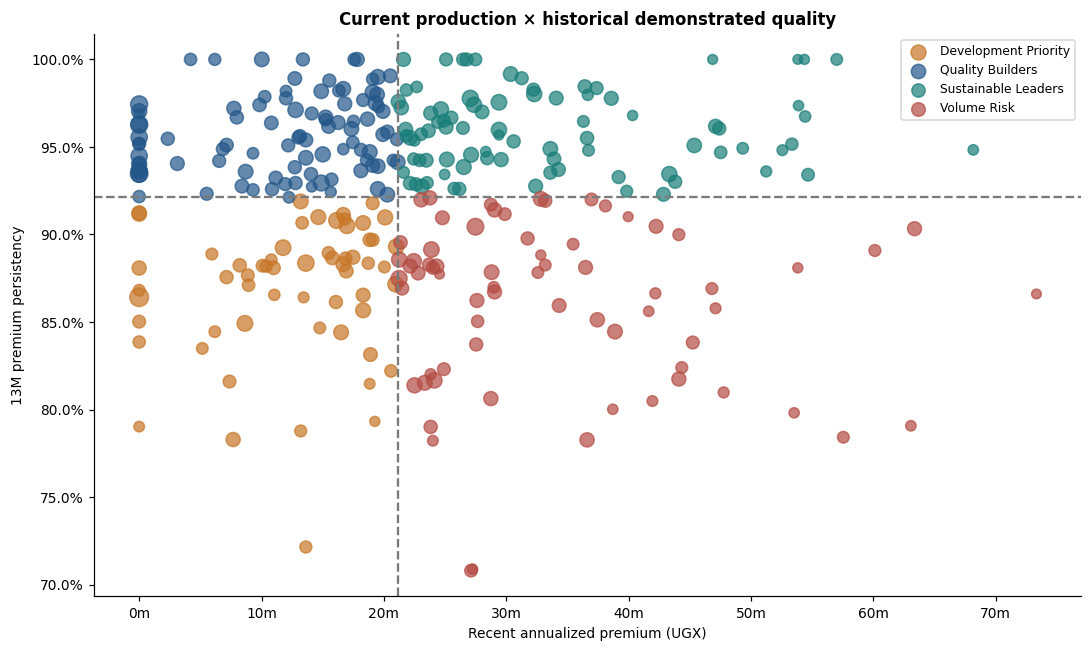

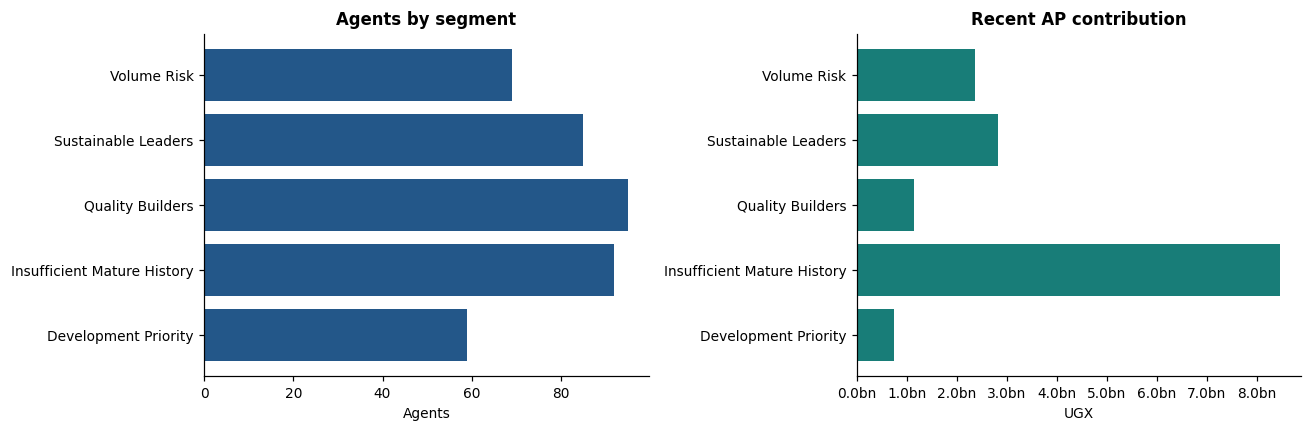

,segment,agent_count,share_of_segmentation_population,recent_policies,recent_annualized_premium,eligible_13m_policies,count_persistency_13m,premium_persistency_13m
0,Development Priority,59,0.14750000000000000000,254,7.376400e+08,3333,0.88568856885688568857,0.87366683371164106948
1,Insufficient Mature History,92,0.23000000000000000000,2792,8.469360e+09,269,0.89591078066914498141,0.89467033375455288783
2,Quality Builders,95,0.23750000000000000000,402,1.133280e+09,5693,0.95204637273845072897,0.95650822151812506768
3,Sustainable Leaders,85,0.21250000000000000000,893,2.822220e+09,4398,0.95702592087312414734,0.95913210532263532603
4,Volume Risk,69,0.17250000000000000000,745,2.360460e+09,3513,0.87361229718189581554,0.86403273296523817866


In [3]:
agents = numeric(
    data["agent_segmentation"],
    ["recent_annualized_premium", "premium_persistency_13m", "eligible_13m_policies"],
)
eligible = agents.query("sufficient_history == True").copy()
colors = {
    "Sustainable Leaders": TEAL,
    "Volume Risk": RED,
    "Quality Builders": BLUE,
    "Development Priority": ORANGE,
}
fig, ax = plt.subplots(figsize=(10, 6))
for segment, subset in eligible.groupby("segment"):
    ax.scatter(
        subset.recent_annualized_premium,
        subset.premium_persistency_13m,
        s=20 + subset.eligible_13m_policies,
        alpha=0.7,
        label=segment,
        color=colors[segment],
    )
ax.axvline(float(thresholds.production_benchmark.iloc[0]), color=GREY, linestyle="--")
ax.axhline(float(thresholds.quality_benchmark.iloc[0]), color=GREY, linestyle="--")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda value, _: f"{value / 1e6:.0f}m"))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(
    xlabel="Recent annualized premium (UGX)",
    ylabel="13M premium persistency",
    title="Current production × historical demonstrated quality",
)
ax.legend(fontsize=8)
finish(fig, "01_production_quality_quadrant")

agency = data["segment_summary"].query("grain == 'Agency'").copy()
agency = numeric(agency, ["agent_count", "recent_annualized_premium"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(agency.segment, agency.agent_count, color=BLUE)
axes[0].set(title="Agents by segment", xlabel="Agents")
axes[1].barh(agency.segment, agency.recent_annualized_premium, color=TEAL)
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda value, _: f"{value / 1e9:.1f}bn"))
axes[1].set(title="Recent AP contribution", xlabel="UGX")
finish(fig, "02_segment_distribution_contribution")
display(
    agency[
        [
            "segment",
            "agent_count",
            "share_of_segmentation_population",
            "recent_policies",
            "recent_annualized_premium",
            "eligible_13m_policies",
            "count_persistency_13m",
            "premium_persistency_13m",
        ]
    ]
)

## 9. Region and unit composition

Composition uses all snapshot agents, including insufficient-history agents.
Current assignment is a limitation, not a historical transfer reconstruction.

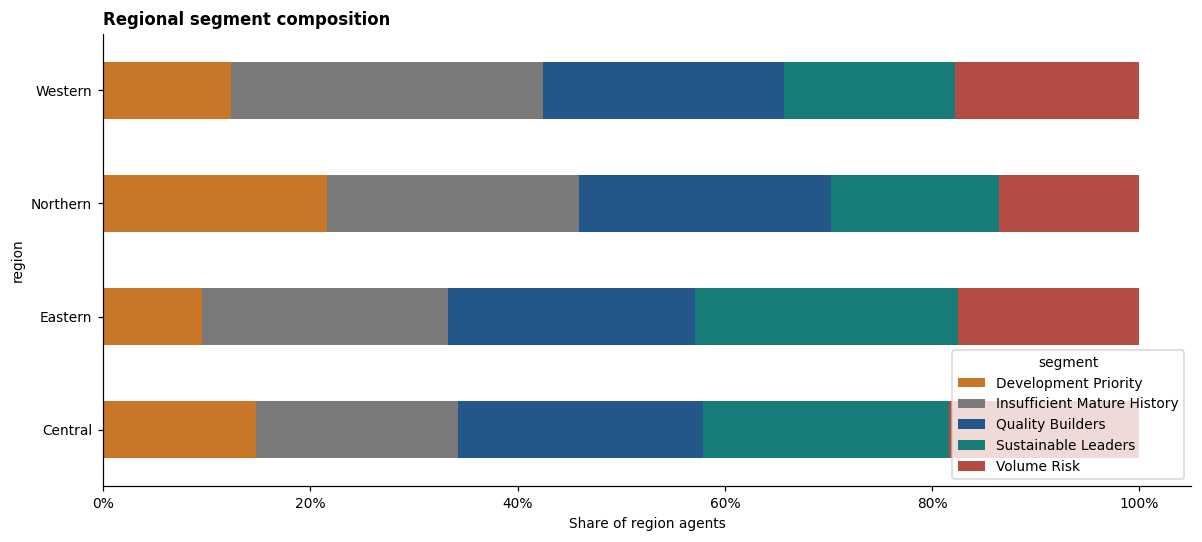

,agency_name,segment,agent_count,share_of_segmentation_population,recent_annualized_premium,premium_persistency_13m
25,Kampala Central,Development Priority,8,0.26666666666666666667,89880000.00,0.88153119756506809225
26,Kampala Central,Insufficient Mature History,4,0.13333333333333333333,483600000.00,0.91564417177914110429
27,Kampala Central,Quality Builders,4,0.13333333333333333333,55020000.00,0.96163349347975291695
28,Kampala Central,Sustainable Leaders,8,0.26666666666666666667,328140000.00,0.96516413053880754139
29,Kampala Central,Volume Risk,6,0.20000000000000000000,213120000.00,0.84475288242637879122
30,Kampala East,Development Priority,4,0.11764705882352941176,68880000.00,0.86624622257259230062
31,Kampala East,Insufficient Mature History,5,0.14705882352941176471,566340000.00,1.00000000000000000000
32,Kampala East,Quality Builders,14,0.41176470588235294118,204060000.00,0.95830002320963457720
33,Kampala East,Sustainable Leaders,7,0.20588235294117647059,223380000.00,0.94992908676080656102
34,Kampala East,Volume Risk,4,0.11764705882352941176,155280000.00,0.89061438415995341163


In [4]:
regions = numeric(
    data["segment_summary"].query("grain == 'Region'"),
    ["share_of_segmentation_population"],
)
pivot = regions.pivot(
    index="region", columns="segment", values="share_of_segmentation_population"
).fillna(0)
pivot.plot(
    kind="barh", stacked=True, figsize=(11, 5), color=[colors.get(c, GREY) for c in pivot.columns]
)
plt.gca().xaxis.set_major_formatter(mtick.PercentFormatter(1))
plt.title("Regional segment composition", loc="left")
plt.xlabel("Share of region agents")
finish(plt.gcf(), "03_region_composition")
display(
    data["segment_summary"].query("grain == 'Unit'")[
        [
            "agency_name",
            "segment",
            "agent_count",
            "share_of_segmentation_population",
            "recent_annualized_premium",
            "premium_persistency_13m",
        ]
    ]
)

## 10–11. Agent drill-down and cohort-aligned support

Drill-downs retain mature denominators. The cohort-aligned table connects volume
and quality on the same mature policies, but does not replace the recent-production
management view.

In [5]:
orders = {
    "Sustainable Leaders": ("recent_annualized_premium", False),
    "Volume Risk": ("recent_annualized_premium", False),
    "Quality Builders": ("premium_persistency_13m", False),
    "Development Priority": ("eligible_13m_policies", False),
    "Insufficient Mature History": ("recent_annualized_premium", False),
}
for segment, (field, ascending) in orders.items():
    print(segment)
    display(
        agents.query("segment == @segment")
        .sort_values(field, ascending=ascending)
        .head(10)[
            [
                "agent_id",
                "agency_name",
                "recent_policies",
                "recent_annualized_premium",
                "eligible_13m_policies",
                "count_persistency_13m",
                "premium_persistency_13m",
            ]
        ]
    )
display(
    data["cohort_aligned_agent_quality"]
    .sort_values("cohort_annualized_premium", ascending=False)
    .head(10)
)

Sustainable Leaders


,agent_id,agency_name,recent_policies,recent_annualized_premium,eligible_13m_policies,count_persistency_13m,premium_persistency_13m
215,A0216,Kampala Central,25,68160000.0,26,0.96153846153846153846,0.948328
102,A0103,Jinja,18,57000000.0,37,1.00000000000000000000,1.000000
43,A0044,Mbale,13,54660000.0,47,0.93617021276595744681,0.934134
178,A0179,Jinja,17,54420000.0,34,0.97058823529411764706,0.967425
205,A0206,Mbale,16,54360000.0,23,1.00000000000000000000,1.000000
380,A0381,Wakiso,17,53880000.0,25,0.96000000000000000000,0.973615
13,A0014,Entebbe,18,53820000.0,20,1.00000000000000000000,1.000000
1,A0002,Mbale,13,53340000.0,43,0.93023255813953488372,0.951620
110,A0111,Wakiso,17,52560000.0,29,0.93103448275862068966,0.948159
268,A0269,Kampala East,15,51240000.0,31,0.93548387096774193548,0.936027


Volume Risk


,agent_id,agency_name,recent_policies,recent_annualized_premium,eligible_13m_policies,count_persistency_13m,premium_persistency_13m
86,A0087,Mbale,20,73320000.0,20,0.90000000000000000000,0.866034
345,A0346,Fort Portal,18,63360000.0,63,0.88888888888888888889,0.903312
84,A0085,Kampala North,17,63060000.0,26,0.80769230769230769231,0.790715
144,A0145,Fort Portal,17,60120000.0,40,0.90000000000000000000,0.890850
292,A0293,Kampala Central,12,57540000.0,38,0.78947368421052631579,0.784185
336,A0337,Kampala North,22,53820000.0,23,0.82608695652173913043,0.880933
381,A0382,Fort Portal,17,53520000.0,25,0.80000000000000000000,0.798125
135,A0136,Gulu,16,47760000.0,31,0.83870967741935483871,0.809786
198,A0199,Lira,13,47100000.0,30,0.90000000000000000000,0.857833
211,A0212,Kampala Central,16,46800000.0,39,0.84615384615384615385,0.869107


Quality Builders


...

Development Priority


,agent_id,agency_name,recent_policies,recent_annualized_premium,eligible_13m_policies,count_persistency_13m,premium_persistency_13m
325,A0326,Lira,0,0.0,130,0.86153846153846153846,0.864188
271,A0272,Kampala Central,6,13620000.0,93,0.89247311827956989247,0.883664
308,A0309,Kampala Central,6,16140000.0,88,0.89772727272727272727,0.908004
129,A0130,Lira,4,8640000.0,85,0.83529411764705882353,0.849234
39,A0040,Wakiso,6,16980000.0,84,0.89285714285714285714,0.904976
377,A0378,Entebbe,4,11760000.0,83,0.86746987951807228916,0.892471
276,A0277,Fort Portal,6,21000000.0,80,0.91250000000000000000,0.893020
264,A0265,Gulu,6,20940000.0,79,0.89873417721518987342,0.871602
67,A0068,Kampala Central,8,20100000.0,76,0.92105263157894736842,0.909752
222,A0223,Masaka,7,18300000.0,74,0.86486486486486486486,0.856667


Insufficient Mature History


,agent_id,agency_name,recent_policies,recent_annualized_premium,eligible_13m_policies,count_persistency_13m,premium_persistency_13m
340,A0341,Lira,92,269340000.0,0,None,NaN
97,A0098,Lira,80,262740000.0,0,None,NaN
165,A0166,Kampala North,73,224940000.0,0,None,NaN
181,A0182,Kampala East,64,222000000.0,0,None,NaN
21,A0022,Mbarara,71,220380000.0,0,None,NaN
259,A0260,Kampala North,75,213360000.0,0,None,NaN
95,A0096,Lira,67,197400000.0,0,None,NaN
301,A0302,Kampala Central,61,193800000.0,0,None,NaN
330,A0331,Gulu,60,184920000.0,0,None,NaN
196,A0197,Fort Portal,62,180480000.0,0,None,NaN


,agent_id,cohort_issue_start,cohort_issue_end,cohort_policies,cohort_annualized_premium,persistent_13m_policies,persistent_13m_annualized_premium,count_persistency_13m,premium_persistency_13m
275,A0326,2024-03-18,2024-10-06,130,400260000.00,112,345900000.00,0.86153846153846153846,0.86418827761954729426
282,A0335,2023-01-05,2023-05-21,104,343620000.00,100,330780000.00,0.96153846153846153846,0.96263314126069495373
19,A0023,2024-03-07,2024-08-31,111,330180000.00,103,308640000.00,0.92792792792792792793,0.93476285662365982192
224,A0268,2023-03-08,2024-11-02,103,318120000.00,100,309960000.00,0.97087378640776699029,0.97434930215013202565
12,A0015,2023-01-02,2023-04-03,94,300960000.00,90,287580000.00,0.95744680851063829787,0.95554226475279106858
4,A0005,2023-01-02,2024-01-26,93,287400000.00,88,271560000.00,0.94623655913978494624,0.94488517745302713987
315,A0377,2023-01-22,2024-12-21,93,284760000.00,88,266700000.00,0.94623655913978494624,0.93657817109144542773
212,A0247,2023-01-20,2025-08-01,82,270060000.00,71,220560000.00,0.86585365853658536585,0.81670739835592090647
99,A0116,2024-01-11,2025-07-31,92,269760000.00,89,259800000.00,0.96739130434782608696,0.96307829181494661922
228,A0272,2023-02-05,2025-07-24,93,269220000.00,83,237900000.00,0.89247311827956989247,0.88366391798529084021


## 12–16. Incentive design and production comparisons

The roster comes only from `incentives`. Equal calendar-month windows are used.
Mid-Year's full After period is unavailable; August is shown only in its separate
partial row. Qualification is the stored synthetic flag and is not proof of
threshold attainment.

,roster_agents,qualified_agents
campaign_name,,
Mid-Year Agency Challenge,250,118
Protection Push,250,113
Q4 Growth Sprint,250,105


,campaign_name,period_label,period_start,period_end,window_status,primary_comparable
0,Mid-Year Agency Challenge,Before,2026-04-01,2026-05-31,Complete,True
1,Mid-Year Agency Challenge,During,2026-06-01,2026-07-31,Complete,True
2,Mid-Year Agency Challenge,After,2026-08-01,2026-09-30,Unavailable,False
3,Mid-Year Agency Challenge,Partial post (August only),2026-08-01,2026-08-31,Partial,False
4,Protection Push,Before,2026-01-01,2026-02-28,Complete,True
5,Protection Push,During,2026-03-01,2026-04-30,Complete,True
6,Protection Push,After,2026-05-01,2026-06-30,Complete,True
7,Q4 Growth Sprint,Before,2025-07-01,2025-09-30,Complete,True
8,Q4 Growth Sprint,During,2025-10-01,2025-12-31,Complete,True
9,Q4 Growth Sprint,After,2026-01-01,2026-03-31,Complete,True


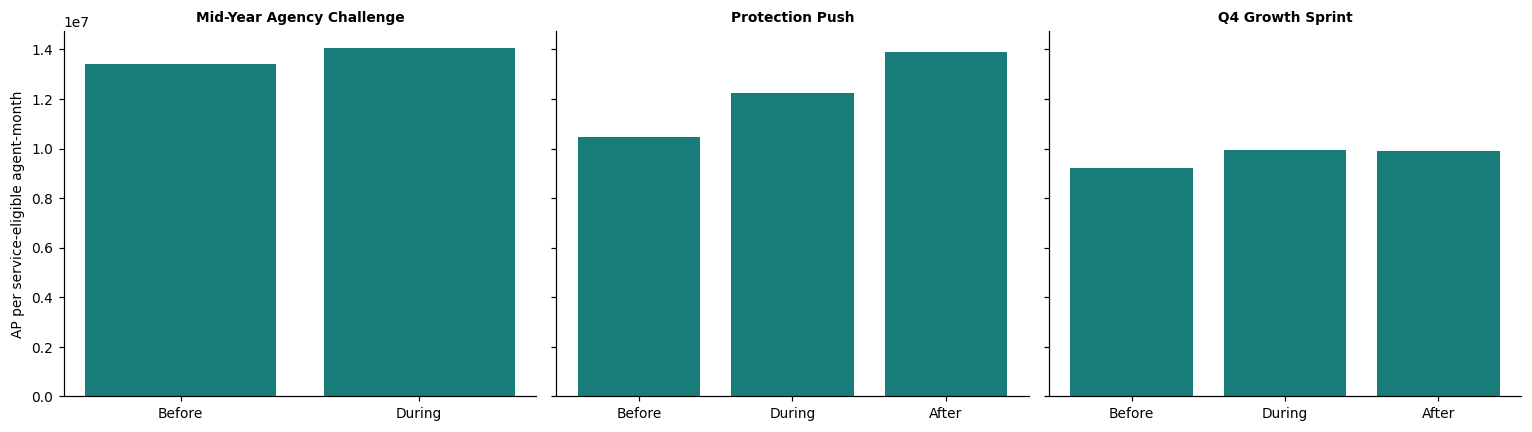

,campaign_name,period_label,comparison_group,agents,service_agent_months,policies_per_agent_month,annualized_premium_per_agent_month
0,Mid-Year Agency Challenge,Before,Campaign roster,250,498.0,4.3433734939759036,1.340470e+07
1,Mid-Year Agency Challenge,Before,Descriptive comparison group,127,249.0,3.7429718875502008,1.114145e+07
2,Mid-Year Agency Challenge,During,Campaign roster,250,498.0,4.5943775100401606,1.404651e+07
3,Mid-Year Agency Challenge,During,Descriptive comparison group,124,247.0,4.5991902834008097,1.408130e+07
8,Protection Push,Before,Campaign roster,239,472.0,3.4830508474576271,1.046758e+07
9,Protection Push,Before,Descriptive comparison group,123,244.0,3.1393442622950820,9.605902e+06
10,Protection Push,During,Campaign roster,250,493.0,4.0202839756592292,1.223112e+07
11,Protection Push,During,Descriptive comparison group,124,246.0,3.5975609756097561,1.104171e+07
12,Protection Push,After,Campaign roster,246,491.0,4.5193482688391039,1.387967e+07
13,Protection Push,After,Descriptive comparison group,129,258.0,4.3217054263565891,1.302791e+07


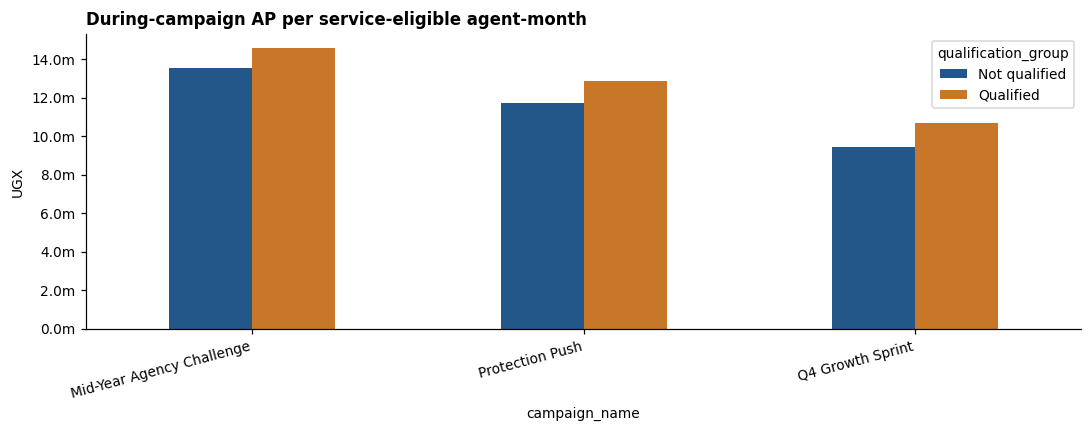

In [6]:
roster = data["campaign_roster"]
display(
    roster.groupby("campaign_name").agg(
        roster_agents=("agent_id", "nunique"), qualified_agents=("qualified", "sum")
    )
)
display(
    data["campaign_periods"][
        [
            "campaign_name",
            "period_label",
            "period_start",
            "period_end",
            "window_status",
            "primary_comparable",
        ]
    ]
)

summary = data["campaign_summary"].query("primary_comparable == True").copy()
summary = numeric(summary, ["annualized_premium_per_agent_month"])
roster_summary = summary.query("comparison_group == 'Campaign roster'")
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (campaign, subset) in zip(axes, roster_summary.groupby("campaign_name"), strict=True):
    subset = subset.sort_values("period_order")
    ax.bar(subset.period_label, subset.annualized_premium_per_agent_month, color=TEAL)
    ax.set_title(campaign, fontsize=9)
axes[0].set_ylabel("AP per service-eligible agent-month")
finish(fig, "04_campaign_before_during_after")
display(
    summary[
        [
            "campaign_name",
            "period_label",
            "comparison_group",
            "agents",
            "service_agent_months",
            "policies_per_agent_month",
            "annualized_premium_per_agent_month",
        ]
    ]
)

qualification = data["campaign_qualification_comparison"].query("period_label == 'During'").copy()
qualification = numeric(qualification, ["annualized_premium_per_agent_month"])
pivot = qualification.pivot(
    index="campaign_name",
    columns="qualification_group",
    values="annualized_premium_per_agent_month",
)
pivot.plot(kind="bar", figsize=(10, 4), color=[BLUE, ORANGE])
plt.gca().yaxis.set_major_formatter(mtick.FuncFormatter(lambda value, _: f"{value / 1e6:.1f}m"))
plt.title("During-campaign AP per service-eligible agent-month", loc="left")
plt.ylabel("UGX")
plt.xticks(rotation=15, ha="right")
finish(plt.gcf(), "05_qualification_comparison")

## 17–18. Campaign retention follow-up and maturity coverage

Campaign-issued policies require both a rostered selling agent and an in-window
issue date. Follow-up reuses Phase 4. Partial maturity remains visible but is not
used as a fully comparable campaign result.

,campaign_name,milestone_months,campaign_policies,milestone_mature_policies,maturity_coverage,maturity_status,count_persistency,premium_persistency,primary_comparable
0,Mid-Year Agency Challenge,3,2288,36,0.015734,Partial,1.00000000000000000000,1.000000,False
1,Mid-Year Agency Challenge,6,2288,0,0.000000,Not mature,None,NaN,False
2,Mid-Year Agency Challenge,13,2288,0,0.000000,Not mature,None,NaN,False
3,Protection Push,3,1982,1982,1.000000,Complete,0.99899091826437941473,0.999035,True
4,Protection Push,6,1982,41,0.020686,Partial,0.95121951219512195122,0.938981,False
5,Protection Push,13,1982,0,0.000000,Not mature,None,NaN,False
6,Q4 Growth Sprint,3,2412,2412,1.000000,Complete,0.99917081260364842454,0.998872,True
7,Q4 Growth Sprint,6,2412,2412,1.000000,Complete,0.96558872305140961857,0.969233,True
8,Q4 Growth Sprint,13,2412,0,0.000000,Not mature,None,NaN,False


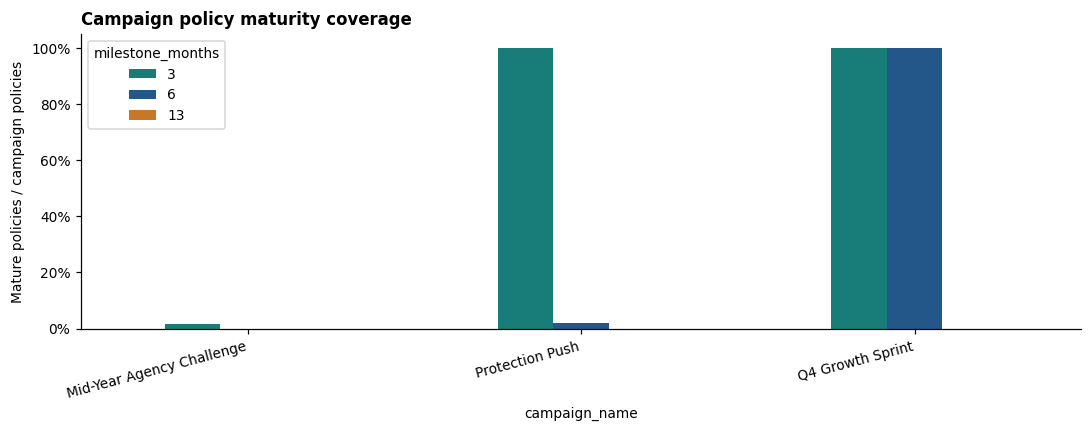

,campaign_name,milestone_months,eligible_policies,persistent_policies,count_persistency,premium_persistency
3,Protection Push,3,1982,1980,0.99899091826437941473,0.999035
6,Q4 Growth Sprint,3,2412,2410,0.99917081260364842454,0.998872
7,Q4 Growth Sprint,6,2412,2329,0.96558872305140961857,0.969233


In [7]:
maturity = data["campaign_maturity"].copy()
maturity = numeric(maturity, ["maturity_coverage", "premium_persistency"])
display(
    maturity[
        [
            "campaign_name",
            "milestone_months",
            "campaign_policies",
            "milestone_mature_policies",
            "maturity_coverage",
            "maturity_status",
            "count_persistency",
            "premium_persistency",
            "primary_comparable",
        ]
    ]
)
pivot = maturity.pivot(
    index="campaign_name", columns="milestone_months", values="maturity_coverage"
)
pivot.plot(kind="bar", figsize=(10, 4), color=[TEAL, BLUE, ORANGE])
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1))
plt.title("Campaign policy maturity coverage", loc="left")
plt.ylabel("Mature policies / campaign policies")
plt.xticks(rotation=15, ha="right")
finish(plt.gcf(), "06_campaign_maturity_coverage")

complete = maturity.query("primary_comparable == True")
display(
    complete[
        [
            "campaign_name",
            "milestone_months",
            "eligible_policies",
            "persistent_policies",
            "count_persistency",
            "premium_persistency",
        ]
    ]
)

## 19–20. Management interpretation and analytical limitations

**Observation →** The executed segment distribution separates high-volume agents
with stronger demonstrated quality from high-volume agents with weaker quality.
**Diagnosis →** Production and historical quality are distinct dimensions with
different cohort timing. **Business implication →** Production recognition and
retention intervention should not use one ranking. **Possible management action →**
Protect Sustainable Leader practices, review Volume Risk cases with denominator
context, coach Quality Builders on current production, and prioritize Development
Priority reviews without stigmatizing labels.

**Observation →** Production differs across before/during/after windows and
recorded qualification groups. **Diagnosis →** Roster selection, synthetic
qualification, seasonality, and agent mix can coexist with campaign timing.
**Business implication →** The patterns cannot establish campaign impact or cost
effectiveness. **Possible management action →** Use the descriptive results to
form operational hypotheses and design prospective evaluation criteria.

**Observation →** Follow-up maturity differs materially by campaign and milestone.
**Diagnosis →** Only the explicitly complete cells support like-for-like retention
reporting at this snapshot. **Business implication →** A headline cross-campaign
13M comparison would be invalid. **Possible management action →** refresh the
analysis after the remaining cohorts mature.

All data are synthetic. Unit attribution is current, qualification is recorded
rather than reconstructed, annualized premium is not cash or profit, partial
windows are excluded from primary comparisons, and no causal or predictive claim
is made.